# 定义损失函数：传入参数向量（二元）

In [76]:
import torch
from torch.optim import SGD
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 定义损失函数 f(w)  0.05 * w0^2 + w1^2
# ============================================================

def f(w):
    #  是一个包含两个元素的张量 [w0, w1]
    return 0.05 * w[0]**2 + w[1] ** 2

# 定义梯度下降训练函数

In [3]:
# ============================================================
# 梯度下降训练函数
# ============================================================
# 参数说明：
#   w        — 需要优化的参数（起点坐标），requires_grad=True
#   optimizer — PyTorch 优化器实例（SGD / SGD+momentum）
#   n_iters  — 迭代次数
# 返回值：
#   w0_list, w1_list — 每一步参数点的坐标轨迹，用于画图对比

def gradient_descent(w, optimizer, n_iters):
    # 用列表保存每一步的参数点坐标，用于后续绘制优化路径
    w0_list = []
    w1_list = []
    for i in range(n_iters):
        # 记录当前参数位置（.item() 将单元素张量转为 Python 数值）
        w0_list.append(w[0].item())
        w1_list.append(w[1].item())

        # 第一步：前向传播，计算损失值
        loss = f(w)

        # 第二步：反向传播，计算梯度（loss 对 x 的偏导数）
        # 此时 x.grad 中存储了 ∂loss/∂x0 和 ∂loss/∂x1
        loss.backward()

        # 第三步：优化器根据梯度更新参数 x
        # SGD:        x = x - lr * grad
        # SGD+momentum: v = momentum*v + grad; x = x - lr*v
        optimizer.step()

        # 第四步：梯度清零，防止梯度累加
        # 默认会累加梯度，每次迭代前必须清零
        optimizer.zero_grad()
    return w0_list, w1_list


# 训练超参数设置

In [78]:
# ============================================================
# 训练超参数设置
# ============================================================
lr = 0.9        # 学习率：控制每一步参数更新的步长
n_iters = 500    # 迭代次数：优化过程的总步数

## 初始化训练参考
start_position=[-7.0, 2]# 初始参数：起点设置在 (-7, 2)，

# 对比不同的优化器 SGD

In [79]:
# ============================================================
# 方法 1：普通 SGD（随机梯度下降）
# ===========================================================
# SGD 更新公式：x_new = x_old - learning_rate * gradient
# 特点：
#   - 每一步只沿着当前梯度的反方向更新
#   - 学习率固定，无法自适应调整
sgd_start_w = torch.tensor(start_position, requires_grad=True)
optimizer = SGD([sgd_start_w], lr=lr)
sgd_w0_list, sgd_w1_list = gradient_descent(sgd_start_w, optimizer, n_iters)



# 2. 动量法

In [81]:
# ============================================================
# 方法 2：带动量的 SGD（SGD with Momentum）
# ============================================================
# 动量更新公式：
#   v_t = momentum * v_{t-1} + gradient    （速度更新：累加历史梯度）
#   x_new = x_old - learning_rate * v_t    （参数更新：用速度替代当前梯度）
#
# 核心思想——类比物理学：
#   - 梯度 决定方向变化
#   - momentum 参数（0.1）相当于"惯性系数"，控制历史方向保留多少
#
# 为什么能加速收敛？
#   - x0 方向（平缓）：历史梯度方向一致，动量累加 → 加速前进
#   - x1 方向（陡峭）：来回震荡的梯度相互抵消 → 抑制震荡
#   - 效果：更快的水平前进速度 + 更小的垂直震荡幅度
#

# momentum=0.1 表示每步保留 10% 的历史速度
momentum_start_w = torch.tensor(start_position, requires_grad=True)
optimizer = SGD([momentum_start_w], lr=lr, momentum=0.1)
momentum_x0_list, momentum_x1_list = gradient_descent(momentum_start_w, optimizer, n_iters)

print(momentum_x0_list)

[-7.0, -6.369999885559082, -5.733699798583984, -5.154036998748779, -4.63220739364624, -4.163125991821289, -3.7415363788604736, -3.3626391887664795, -3.0221118927001953, -2.716068983078003, -2.441018581390381, -2.193821907043457, -1.9716582298278809, -1.7719926834106445, -1.592546820640564, -1.4312729835510254, -1.286331057548523, -1.1560670137405396, -1.038994550704956, -0.9337778091430664, -0.8392161130905151, -0.7542304992675781, -0.6778512001037598, -0.6092066764831543, -0.5475136041641235, -0.4920680820941925, -0.44223740696907043, -0.3974529802799225, -0.35720378160476685, -0.32103052735328674, -0.2885204553604126, -0.25930261611938477, -0.2330435961484909, -0.20944376289844513, -0.18823383748531342, -0.1691717952489853, -0.15204012393951416, -0.13664335012435913, -0.12280577421188354, -0.1103694960474968, -0.09919261187314987, -0.08914759010076523, -0.08011980354785919, -0.0720062404870987, -0.06471432000398636, -0.05816083773970604, -0.05227101594209671, -0.04697764292359352, -0

# 绘制等高线 + 两条优化轨迹对比

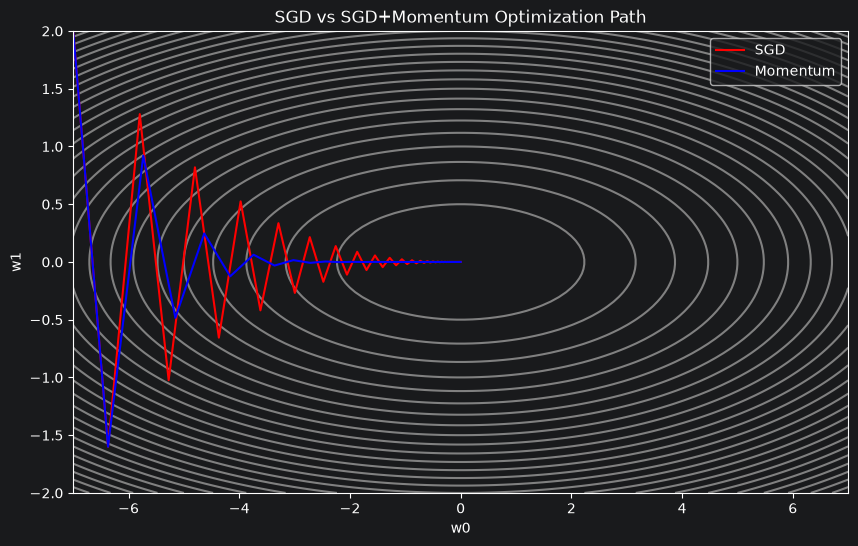

In [75]:
# ============================================================
# 绘制等高线 + 两条优化轨迹
# ============================================================
plt.figure(figsize=(10, 6))

# meshgrid 生成网格点坐标矩阵，用于计算整个平面上每个点的损失值
## x0=[-7,7]范围内100个点,
## x1=[-2,2]范围内的100个点
w0, w1 = np.meshgrid(np.linspace(-7, 7, 100),
                     np.linspace(-2, 2, 100))
# 计算每个网格点的损失值（用于绘制等高线）
## loss=100*100 的矩阵点 对应函数的值范围
loss = f([w0, w1])
# 绘制等高线：灰色，30 条等高线
# 注意：损失函数最小值在 (0, 0)，等高线呈椭圆形环绕原点
plt.contour(w0, w1, loss, colors='gray', levels=30)

# 用红色绘制 SGD 的优化轨迹
plt.plot(sgd_w0_list, sgd_w1_list, color='r')
# 用蓝色绘制动量法的优化轨迹
plt.plot(momentum_x0_list, momentum_x1_list, color='b')

# 图例说明
plt.legend(['SGD', 'Momentum'])
plt.xlabel('w0')
plt.ylabel('w1')
plt.title('SGD vs SGD+Momentum Optimization Path')
plt.show()

# 总结
引入 “惯性” 概念，利用历史梯度平滑当前更新方向，减少震荡，加速收敛。
因为其会累计历史梯度，也可以有效避免鞍点问题。

缺点：加入动量后，需要重新调整学习率，否则容易发散。